In [1]:
# Cell 1: Install required libraries

!pip install -q pandas numpy scikit-learn matplotlib seaborn wfdb pillow requests openpyxl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 4.9 MB/s eta 0:00:00


In [2]:
# Cell 2: Import libraries

import os
import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

import wfdb

print("All libraries imported successfully.")

All libraries imported successfully.


In [5]:
# Cell 3: Download Cleveland Heart Disease Dataset from UCI

import urllib.request
import pandas as pd
import os

# Official UCI Cleveland dataset
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"

file_path = "processed.cleveland.data"

urllib.request.urlretrieve(url, file_path)

# Official Cleveland dataset column names
columns = [
    "age",
    "sex",
    "cp",
    "trestbps",
    "chol",
    "fbs",
    "restecg",
    "thalach",
    "exang",
    "oldpeak",
    "slope",
    "ca",
    "thal",
    "target"
]

# Load dataset
heart_df = pd.read_csv(
    file_path,
    names=columns,
    na_values="?"
)

print("Dataset loaded successfully!")
print("Shape:", heart_df.shape)

display(heart_df.head())

Dataset loaded successfully!
Shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [6]:
# Cell 4: Dataset inspection

print("Dataset Shape:")
print(heart_df.shape)

print("\nColumn Names:")
print(heart_df.columns.tolist())

print("\nData Types:")
print(heart_df.dtypes)

print("\nMissing Values:")
print(heart_df.isnull().sum())

print("\nStatistical Summary:")
display(heart_df.describe())

Dataset Shape:
(303, 14)

Column Names:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

Data Types:
age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
target        int64
dtype: object

Missing Values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

Statistical Summary:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.937294
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,1.228536
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,4.000000


In [7]:
# Cell 5: Identify numerical and categorical columns

numerical_columns = heart_df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_columns = heart_df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical Columns:")
print(numerical_columns)

print("\nCategorical Columns:")
print(categorical_columns)

Numerical Columns:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

Categorical Columns:
[]


In [8]:
# Cell 5: Identify numerical and categorical columns

numerical_columns = heart_df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_columns = heart_df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical Columns:")
print(numerical_columns)

print("\nCategorical Columns:")
print(categorical_columns)

Numerical Columns:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

Categorical Columns:
[]


In [9]:
# Cell 7: Convert target to binary classification

# 0  -> No heart disease
# 1-4 -> Heart disease

heart_df["target_binary"] = (
    heart_df["target"] > 0
).astype(int)

print("Binary target distribution:")
print(
    heart_df["target_binary"]
    .value_counts()
    .sort_index()
)

print("\nPercentage distribution:")
print(
    heart_df["target_binary"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Binary target distribution:
target_binary
0    164
1    139
Name: count, dtype: int64

Percentage distribution:
target_binary
0    54.13
1    45.87
Name: proportion, dtype: float64


In [10]:
# Cell 8: Check and handle missing values

print("Missing values before preprocessing:")
display(heart_df.isnull().sum())

print("\nTotal missing values:",
      heart_df.isnull().sum().sum())

Missing values before preprocessing:


,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0



Total missing values: 6


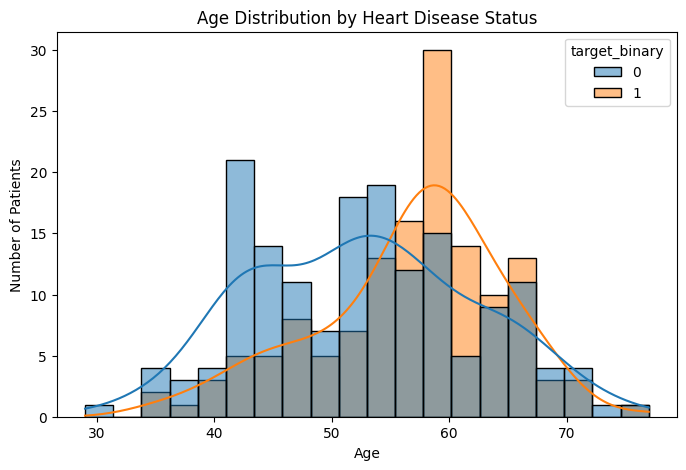

In [11]:
# Cell 9: Basic EDA - Age distribution

plt.figure(figsize=(8, 5))

sns.histplot(
    data=heart_df,
    x="age",
    hue="target_binary",
    bins=20,
    kde=True
)

plt.title("Age Distribution by Heart Disease Status")
plt.xlabel("Age")
plt.ylabel("Number of Patients")

plt.show()

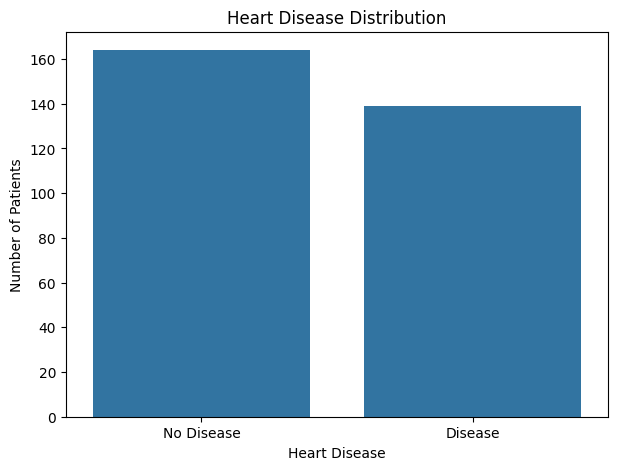

In [12]:
# Cell 10: Target distribution visualization

plt.figure(figsize=(7, 5))

sns.countplot(
    data=heart_df,
    x="target_binary"
)

plt.title("Heart Disease Distribution")
plt.xlabel("Heart Disease")
plt.ylabel("Number of Patients")

plt.xticks(
    [0, 1],
    ["No Disease", "Disease"]
)

plt.show()

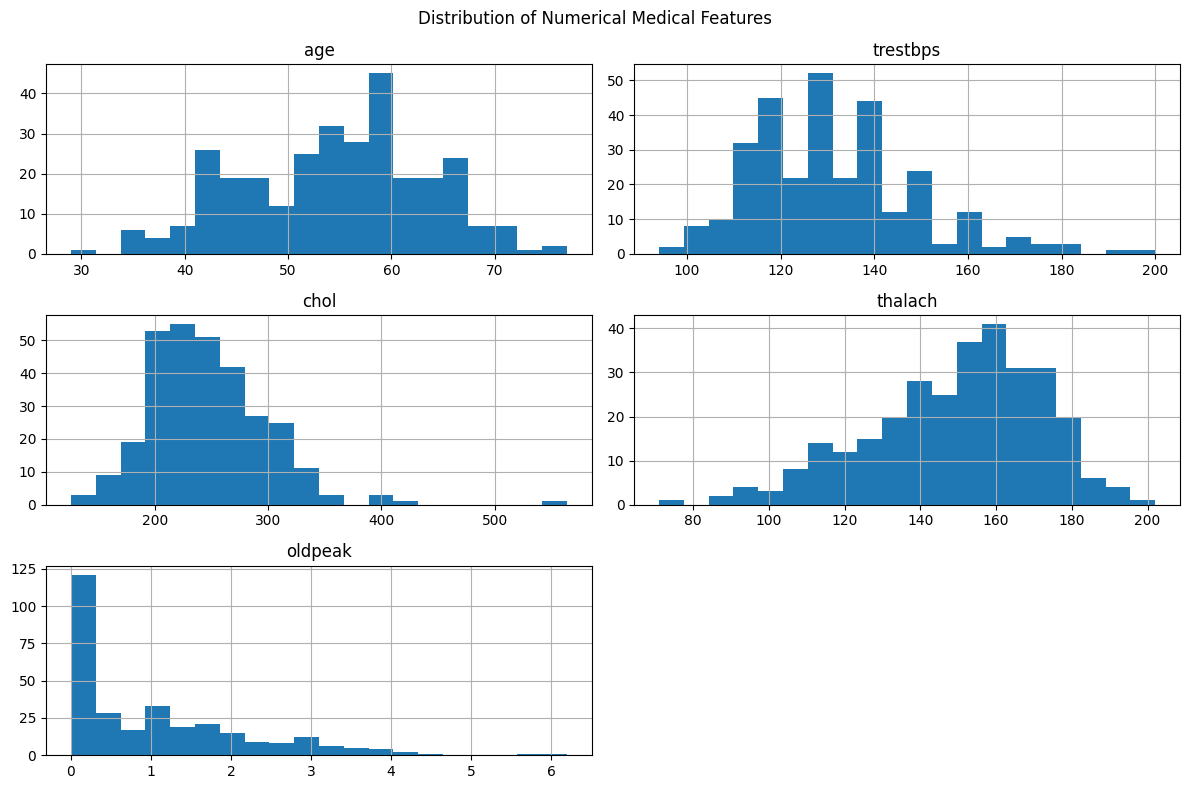

In [13]:
# Cell 11: Numerical feature distributions

numerical_features = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

heart_df[numerical_features].hist(
    figsize=(12, 8),
    bins=20
)

plt.suptitle(
    "Distribution of Numerical Medical Features"
)

plt.tight_layout()
plt.show()

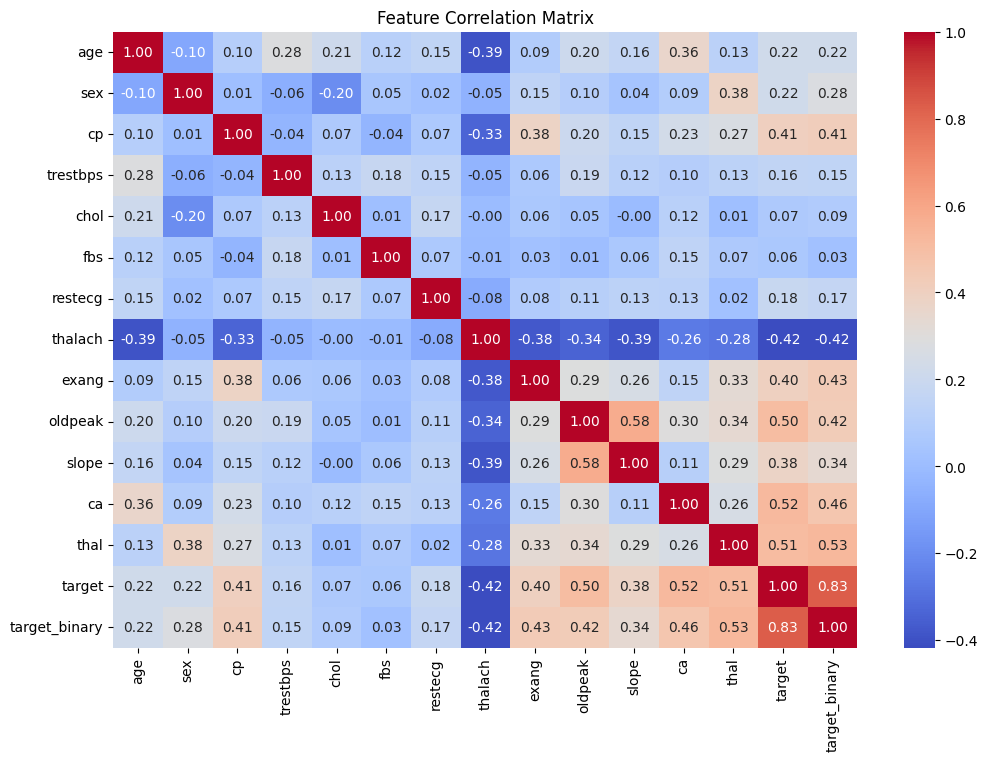

In [14]:
# Cell 12: Correlation matrix

numeric_df = heart_df.select_dtypes(
    include=np.number
)

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Feature Correlation Matrix")

plt.show()

In [15]:
# Cell 13: Identify numerical and categorical features

# Remove target columns
feature_df = heart_df.drop(
    columns=["target", "target_binary"]
)

numerical_features = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

categorical_features = [
    "sex",
    "cp",
    "fbs",
    "restecg",
    "exang",
    "slope",
    "ca",
    "thal"
]

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

Categorical features:
['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']


In [16]:
# Cell 14: Prepare features and target

X = heart_df.drop(
    columns=["target", "target_binary"]
)

y = heart_df["target_binary"]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

Feature matrix shape: (303, 13)
Target shape: (303,)

Features:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']


In [17]:
# Cell 15: Train-test split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training samples: 242
Testing samples : 61

Training class distribution:
target_binary
0    131
1    111
Name: count, dtype: int64

Testing class distribution:
target_binary
0    33
1    28
Name: count, dtype: int64


In [18]:
# Cell 16: Build preprocessing pipeline

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

# Numerical preprocessing
numerical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    )
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "encoder",
        OneHotEncoder(
            handle_unknown="ignore"
        )
    )
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer([
    (
        "numerical",
        numerical_pipeline,
        numerical_features
    ),
    (
        "categorical",
        categorical_pipeline,
        categorical_features
    )
])

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [20]:
# Cell 17: Build Logistic Regression pipeline

model = Pipeline([
    (
        "preprocessor",
        preprocessor
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    )
])

print("Logistic Regression pipeline created.")

Logistic Regression pipeline created.


In [22]:
# Cell 18: Train the model

model.fit(
    X_train,
    y_train
)

print("Model training completed successfully.")

Model training completed successfully.


In [23]:
# Cell 19: Generate predictions

y_pred = model.predict(X_test)

y_probability = model.predict_proba(
    X_test
)[:, 1]

print("Predictions generated successfully.")

print("\nFirst 10 predictions:")
print(y_pred[:10])

print("\nFirst 10 probabilities:")
print(y_probability[:10])

Predictions generated successfully.

First 10 predictions:
[0 1 0 0 0 0 0 0 1 0]

First 10 probabilities:
[0.20929567 0.60145782 0.02148916 0.03334708 0.3118407  0.01557081
 0.11681799 0.34861394 0.72209751 0.34742282]


In [25]:
# Cell 20: Model evaluation

accuracy = accuracy_score(
    y_test,
    y_pred
)

roc_auc = roc_auc_score(
    y_test,
    y_probability
)

print("=" * 40)
print("MODEL PERFORMANCE")
print("=" * 40)

print(f"Accuracy : {accuracy:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "No Disease",
            "Disease"
        ]
    )
)

MODEL PERFORMANCE
Accuracy : 0.8852
ROC-AUC  : 0.9665

Classification Report:
              precision    recall  f1-score   support

  No Disease       0.93      0.85      0.89        33
     Disease       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61



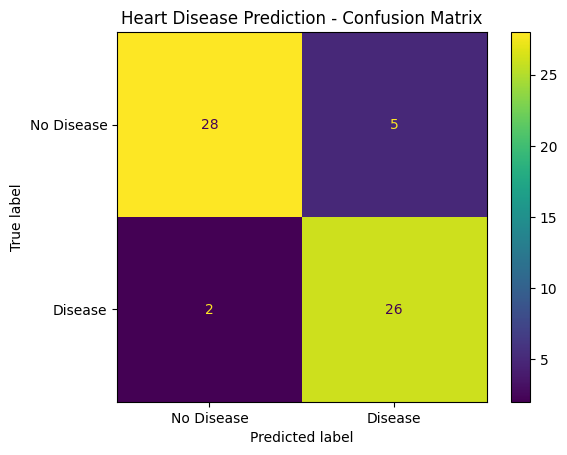

In [26]:
# Cell 21: Confusion matrix

cm = confusion_matrix(
    y_test,
    y_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "No Disease",
        "Disease"
    ]
)

disp.plot()

plt.title(
    "Heart Disease Prediction - Confusion Matrix"
)

plt.show()

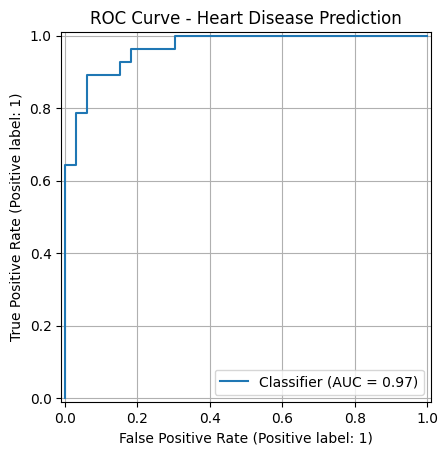

In [27]:
# Cell 22: ROC curve

RocCurveDisplay.from_predictions(
    y_test,
    y_probability
)

plt.title(
    "ROC Curve - Heart Disease Prediction"
)

plt.grid(True)

plt.show()

In [28]:
# Cell 23: Display transformed feature names

feature_names = (
    model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

print(
    "Number of features after preprocessing:",
    len(feature_names)
)

print("\nTransformed features:")

for feature in feature_names:
    print(feature)

Number of features after preprocessing: 28

Transformed features:
numerical__age
numerical__trestbps
numerical__chol
numerical__thalach
numerical__oldpeak
categorical__sex_0.0
categorical__sex_1.0
categorical__cp_1.0
categorical__cp_2.0
categorical__cp_3.0
categorical__cp_4.0
categorical__fbs_0.0
categorical__fbs_1.0
categorical__restecg_0.0
categorical__restecg_1.0
categorical__restecg_2.0
categorical__exang_0.0
categorical__exang_1.0
categorical__slope_1.0
categorical__slope_2.0
categorical__slope_3.0
categorical__ca_0.0
categorical__ca_1.0
categorical__ca_2.0
categorical__ca_3.0
categorical__thal_3.0
categorical__thal_6.0
categorical__thal_7.0


In [29]:
# Cell 24: Analyze model coefficients

coefficients = (
    model
    .named_steps["classifier"]
    .coef_[0]
)

coefficient_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

coefficient_df["Absolute_Importance"] = (
    coefficient_df["Coefficient"]
    .abs()
)

coefficient_df = coefficient_df.sort_values(
    "Absolute_Importance",
    ascending=False
)

display(
    coefficient_df.head(15)
)

,Feature,Coefficient,Absolute_Importance
21,categorical__ca_0.0,-1.498641,1.498641
10,categorical__cp_4.0,1.030561,1.030561
27,categorical__thal_7.0,0.818491,0.818491
5,categorical__sex_0.0,-0.700836,0.700836
6,categorical__sex_1.0,0.690353,0.690353
23,categorical__ca_2.0,0.642171,0.642171
7,categorical__cp_1.0,-0.619176,0.619176
19,categorical__slope_2.0,0.603427,0.603427
9,categorical__cp_3.0,-0.574766,0.574766
25,categorical__thal_3.0,-0.540243,0.540243


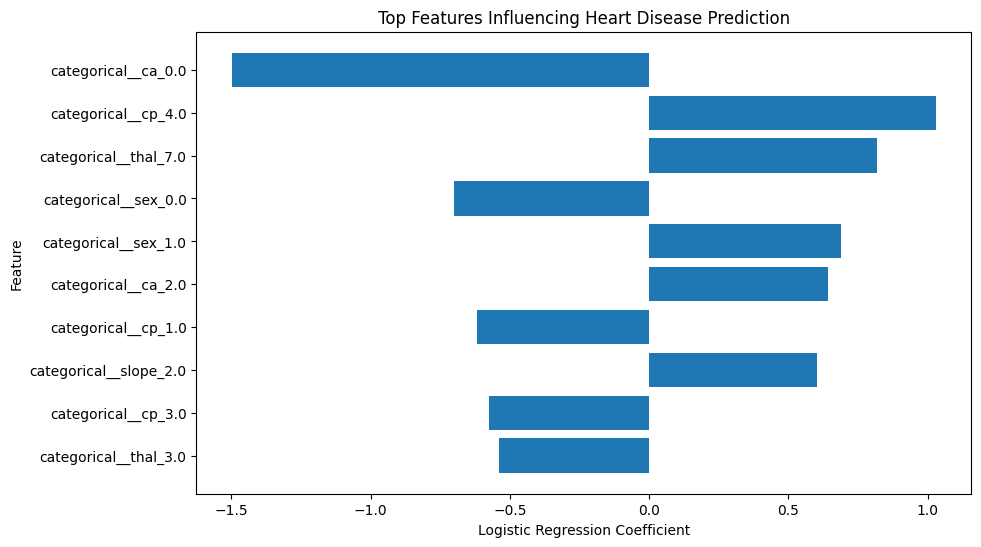

In [30]:
# Cell 25: Visualize important features

top_features = coefficient_df.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)

plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Feature")
plt.title(
    "Top Features Influencing Heart Disease Prediction"
)

plt.gca().invert_yaxis()

plt.show()

In [31]:
# Cell 26: Load MIT-BIH Arrhythmia Database record

record_name = "100"

record = wfdb.rdrecord(
    record_name,
    pn_dir="mitdb"
)

annotation = wfdb.rdann(
    record_name,
    "atr",
    pn_dir="mitdb"
)

print("ECG record loaded successfully!")

print("\nRecord:", record_name)
print("Sampling frequency:", record.fs, "Hz")
print("Number of samples:", record.sig_len)
print("Number of channels:", record.n_sig)
print("Signal names:", record.sig_name)

ECG record loaded successfully!

Record: 100
Sampling frequency: 360 Hz
Number of samples: 650000
Number of channels: 2
Signal names: ['MLII', 'V5']


In [32]:
# Cell 27: Inspect ECG signal

signal = record.p_signal

print("Signal shape:", signal.shape)

print("\nFirst 10 samples:")
display(
    pd.DataFrame(
        signal[:10],
        columns=record.sig_name
    )
)

Signal shape: (650000, 2)

First 10 samples:


,MLII,V5
0,-0.145,-0.065
1,-0.145,-0.065
2,-0.145,-0.065
3,-0.145,-0.065
4,-0.145,-0.065
5,-0.145,-0.065
6,-0.145,-0.065
7,-0.145,-0.065
8,-0.120,-0.080
9,-0.135,-0.080


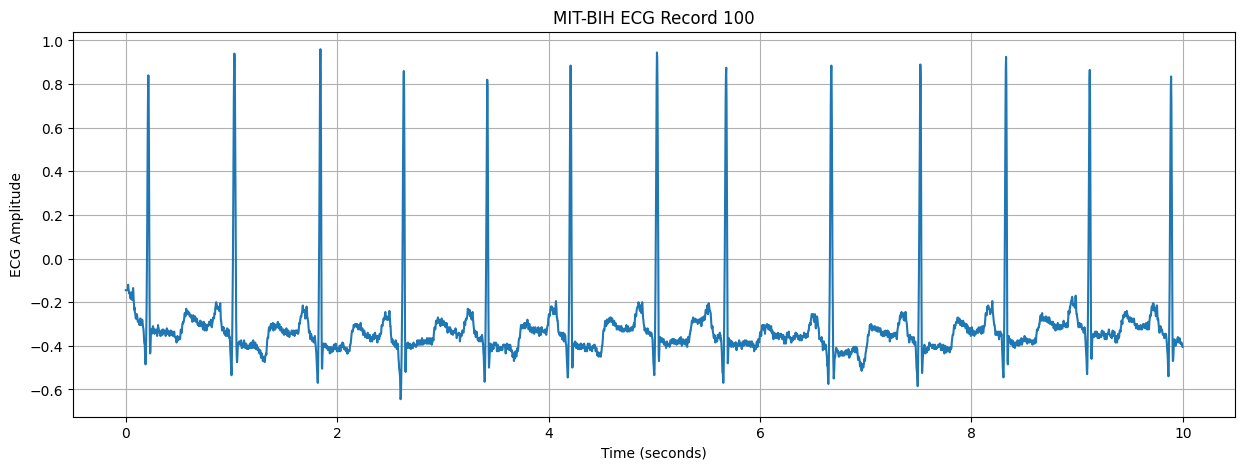

In [34]:
# Cell 28: Plot ECG waveform

sampling_rate = record.fs

duration_seconds = 10

samples = int(
    duration_seconds * sampling_rate
)

time = (
    np.arange(samples)
    / sampling_rate
)

plt.figure(figsize=(15, 5))

plt.plot(
    time,
    signal[:samples, 0]
)

plt.title(
    "MIT-BIH ECG Record 100"
)

plt.xlabel("Time (seconds)")
plt.ylabel("ECG Amplitude")

plt.grid(True)

plt.show()

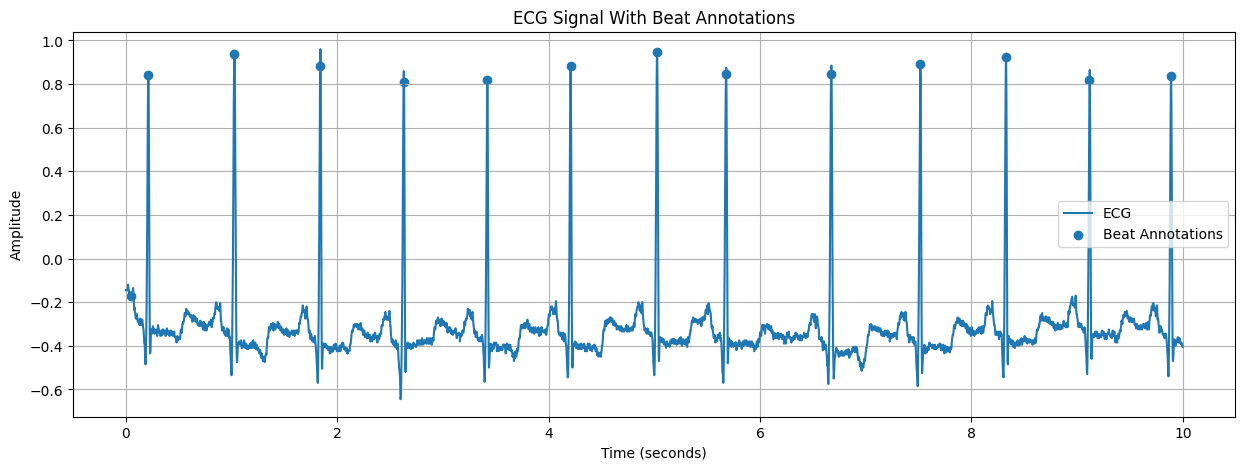

Number of annotations: 14


In [35]:
# Cell 29: ECG waveform with beat annotations

plt.figure(figsize=(15, 5))

plt.plot(
    time,
    signal[:samples, 0],
    label="ECG"
)

annotation_samples = annotation.sample[
    annotation.sample < samples
]

annotation_times = (
    annotation_samples
    / sampling_rate
)

annotation_values = signal[
    annotation_samples,
    0
]

plt.scatter(
    annotation_times,
    annotation_values,
    marker="o",
    label="Beat Annotations"
)

plt.title(
    "ECG Signal With Beat Annotations"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")

plt.legend()
plt.grid(True)

plt.show()

print(
    "Number of annotations:",
    len(annotation_samples)
)

In [36]:
# Cell 30: Calculate RR intervals

beat_samples = np.array(
    annotation.sample
)

rr_intervals = (
    np.diff(beat_samples)
    / sampling_rate
)

print(
    "Number of RR intervals:",
    len(rr_intervals)
)

print("\nFirst 20 RR intervals:")
print(rr_intervals[:20])

print(
    "\nMean RR interval:",
    round(np.mean(rr_intervals), 4),
    "seconds"
)

Number of RR intervals: 2273

First 20 RR intervals:
[0.16388889 0.81388889 0.81111111 0.78888889 0.79166667 0.78888889
 0.81666667 0.65277778 0.99444444 0.84444444 0.81111111 0.78888889
 0.77222222 0.83888889 0.85555556 0.82222222 0.82777778 0.82222222
 0.79444444 0.79722222]

Mean RR interval: 0.7943 seconds


In [37]:
# Cell 31: Calculate average heart rate

mean_rr = np.mean(
    rr_intervals
)

heart_rate = 60 / mean_rr

print(
    f"Average Heart Rate: {heart_rate:.2f} BPM"
)

Average Heart Rate: 75.54 BPM


In [38]:
# Cell 32: Basic HRV statistics

std_rr = np.std(
    rr_intervals
)

rmssd = np.sqrt(
    np.mean(
        np.diff(rr_intervals) ** 2
    )
)

print("=" * 40)
print("ECG / HRV STATISTICS")
print("=" * 40)

print(
    f"Mean RR Interval : {mean_rr:.4f} sec"
)

print(
    f"STD of RR        : {std_rr:.4f} sec"
)

print(
    f"RMSSD            : {rmssd:.4f} sec"
)

print(
    f"Mean Heart Rate  : {heart_rate:.2f} BPM"
)

ECG / HRV STATISTICS
Mean RR Interval : 0.7943 sec
STD of RR        : 0.0506 sec
RMSSD            : 0.0647 sec
Mean Heart Rate  : 75.54 BPM


In [39]:
# Cell 33: Synthetic clinical note

clinical_note = """
Patient is a 58 year old male presenting with chest pain
during physical activity. The patient reports shortness of
breath and occasional dizziness. Blood pressure is elevated
and the patient has a history of high cholesterol. The patient
denies fever or recent infection. ECG examination is recommended
for further cardiovascular assessment.
"""

print(clinical_note)


Patient is a 58 year old male presenting with chest pain
during physical activity. The patient reports shortness of
breath and occasional dizziness. Blood pressure is elevated
and the patient has a history of high cholesterol. The patient
denies fever or recent infection. ECG examination is recommended
for further cardiovascular assessment.



In [41]:
# Cell 34: Clean clinical text

def clean_text(text):

    text = text.lower()

    text = re.sub(
        r"[^a-z0-9\s]",
        " ",
        text
    )

    text = re.sub(
        r"\s+",
        " ",
        text
    )

    return text.strip()


cleaned_note = clean_text(
    clinical_note
)

print(cleaned_note)

patient is a 58 year old male presenting with chest pain during physical activity the patient reports shortness of breath and occasional dizziness blood pressure is elevated and the patient has a history of high cholesterol the patient denies fever or recent infection ecg examination is recommended for further cardiovascular assessment


In [42]:
# Cell 35: Tokenize clinical note

tokens = cleaned_note.split()

print(
    "Number of tokens:",
    len(tokens)
)

print("\nTokens:")
print(tokens)

Number of tokens: 51

Tokens:
['patient', 'is', 'a', '58', 'year', 'old', 'male', 'presenting', 'with', 'chest', 'pain', 'during', 'physical', 'activity', 'the', 'patient', 'reports', 'shortness', 'of', 'breath', 'and', 'occasional', 'dizziness', 'blood', 'pressure', 'is', 'elevated', 'and', 'the', 'patient', 'has', 'a', 'history', 'of', 'high', 'cholesterol', 'the', 'patient', 'denies', 'fever', 'or', 'recent', 'infection', 'ecg', 'examination', 'is', 'recommended', 'for', 'further', 'cardiovascular', 'assessment']


In [44]:
# Cell 36: Remove basic stopwords

stopwords = {
    "the", "is", "a", "an",
    "and", "or", "of", "to",
    "with", "has", "for",
    "on", "in", "during",
    "patient"
}

filtered_tokens = [
    word
    for word in tokens
    if word not in stopwords
]

print("Filtered tokens:")
print(filtered_tokens)

Filtered tokens:
['58', 'year', 'old', 'male', 'presenting', 'chest', 'pain', 'physical', 'activity', 'reports', 'shortness', 'breath', 'occasional', 'dizziness', 'blood', 'pressure', 'elevated', 'history', 'high', 'cholesterol', 'denies', 'fever', 'recent', 'infection', 'ecg', 'examination', 'recommended', 'further', 'cardiovascular', 'assessment']


In [45]:
# Cell 37: Word frequency analysis

word_frequency = Counter(
    filtered_tokens
)

frequency_df = pd.DataFrame(
    word_frequency.items(),
    columns=[
        "Word",
        "Frequency"
    ]
).sort_values(
    "Frequency",
    ascending=False
)

display(frequency_df)

,Word,Frequency
0,58,1
1,year,1
2,old,1
3,male,1
4,presenting,1
5,chest,1
6,pain,1
7,physical,1
8,activity,1
9,reports,1


In [46]:
# Cell 38: Extract clinical keywords

clinical_keywords = [
    "chest pain",
    "shortness of breath",
    "dizziness",
    "blood pressure",
    "cholesterol",
    "ecg",
    "heart",
    "cardiovascular"
]

found_keywords = []

for keyword in clinical_keywords:

    if keyword.lower() in cleaned_note:

        found_keywords.append(
            keyword
        )

print("Detected clinical keywords:")

for keyword in found_keywords:
    print("-", keyword)

Detected clinical keywords:
- chest pain
- shortness of breath
- dizziness
- blood pressure
- cholesterol
- ecg
- cardiovascular


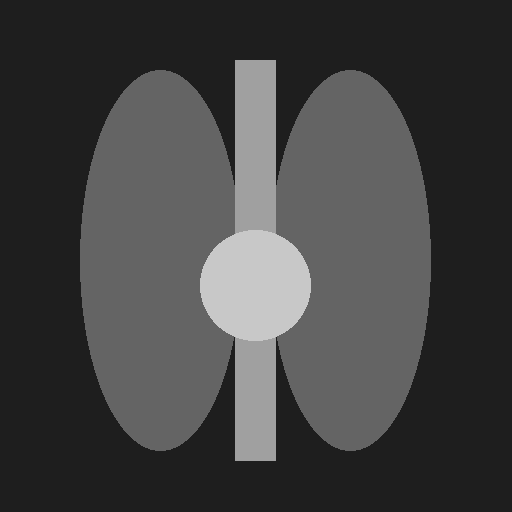

In [47]:
# Cell 39: Generate synthetic medical-style image

from PIL import Image, ImageDraw

width = 512
height = 512

image = Image.new(
    "L",
    (width, height),
    color=30
)

draw = ImageDraw.Draw(image)

# Left lung
draw.ellipse(
    (80, 70, 240, 450),
    fill=100
)

# Right lung
draw.ellipse(
    (270, 70, 430, 450),
    fill=100
)

# Spine
draw.rectangle(
    (235, 60, 275, 460),
    fill=160
)

# Heart region
draw.ellipse(
    (200, 230, 310, 340),
    fill=200
)

display(image)

In [48]:
# Cell 40: Inspect image properties

print("Image format :", image.format)
print("Image size   :", image.size)
print("Image mode   :", image.mode)

image_array = np.array(image)

print("Array shape  :", image_array.shape)
print("Data type    :", image_array.dtype)
print("Minimum pixel:", image_array.min())
print("Maximum pixel:", image_array.max())

Image format : None
Image size   : (512, 512)
Image mode   : L
Array shape  : (512, 512)
Data type    : uint8
Minimum pixel: 30
Maximum pixel: 200


Minimum normalized value: 0.11764705882352941
Maximum normalized value: 0.7843137254901961


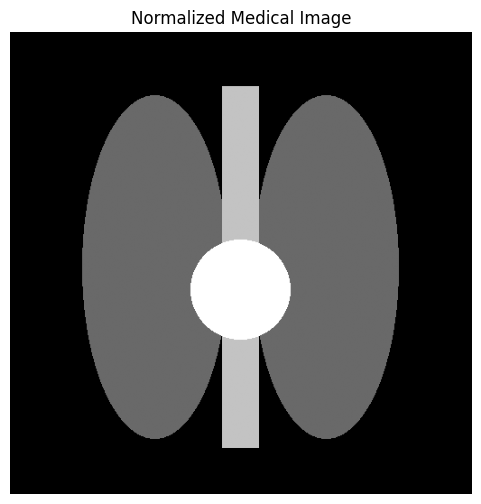

In [49]:
# Cell 41: Normalize image

normalized_image = (
    image_array / 255.0
)

print(
    "Minimum normalized value:",
    normalized_image.min()
)

print(
    "Maximum normalized value:",
    normalized_image.max()
)

plt.figure(figsize=(6, 6))

plt.imshow(
    normalized_image,
    cmap="gray"
)

plt.title(
    "Normalized Medical Image"
)

plt.axis("off")

plt.show()

Original size: (512, 512)
Resized size: (224, 224)


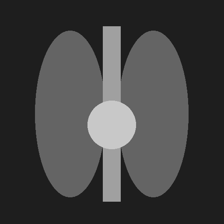

In [50]:
# Cell 42: Resize image

target_size = (
    224,
    224
)

resized_image = image.resize(
    target_size
)

print(
    "Original size:",
    image.size
)

print(
    "Resized size:",
    resized_image.size
)

display(resized_image)

In [52]:
# Cell 43: Create unified patient representation

patient_data = {

    "patient_id": "P001",

    # Tabular features
    "age": 58,
    "sex": 1,

    # ECG features
    "mean_rr": float(mean_rr),
    "heart_rate": float(heart_rate),
    "rmssd": float(rmssd),

    # Text features
    "clinical_keywords": found_keywords,

    # Image information
    "image_width": resized_image.width,
    "image_height": resized_image.height
}

print(
    json.dumps(
        patient_data,
        indent=4
    )
)

{
    "patient_id": "P001",
    "age": 58,
    "sex": 1,
    "mean_rr": 0.7943161265092633,
    "heart_rate": 75.536676138855,
    "rmssd": 0.06467193175692733,
    "clinical_keywords": [
        "chest pain",
        "shortness of breath",
        "dizziness",
        "blood pressure",
        "cholesterol",
        "ecg",
        "cardiovascular"
    ],
    "image_width": 224,
    "image_height": 224
}


In [53]:
# Cell 44: Unified multimodal dataframe

fusion_df = pd.DataFrame([{

    "patient_id":
        patient_data["patient_id"],

    "age":
        patient_data["age"],

    "sex":
        patient_data["sex"],

    "mean_rr":
        patient_data["mean_rr"],

    "heart_rate":
        patient_data["heart_rate"],

    "rmssd":
        patient_data["rmssd"],

    "clinical_keyword_count":
        len(
            patient_data[
                "clinical_keywords"
            ]
        ),

    "image_width":
        patient_data["image_width"],

    "image_height":
        patient_data["image_height"]
}])

display(fusion_df)

,patient_id,age,sex,mean_rr,heart_rate,rmssd,clinical_keyword_count,image_width,image_height
0,P001,58,1,0.794316,75.536676,0.064672,7,224,224


In [54]:
# Cell 45: Demonstrate multimodal patient/time alignment

tabular_metadata = pd.DataFrame({
    "patient_id": ["P001"],
    "timestamp": ["2026-08-20 10:00:00"],
    "age": [58],
    "cholesterol": [240]
})

ecg_metadata = pd.DataFrame({
    "patient_id": ["P001"],
    "timestamp": ["2026-08-20 10:02:00"],
    "heart_rate": [heart_rate],
    "rmssd": [rmssd]
})

text_metadata = pd.DataFrame({
    "patient_id": ["P001"],
    "timestamp": ["2026-08-20 09:55:00"],
    "note": [clinical_note]
})

print("TABULAR DATA")
display(tabular_metadata)

print("ECG DATA")
display(ecg_metadata)

print("TEXT DATA")
display(text_metadata)

TABULAR DATA


,patient_id,timestamp,age,cholesterol
0,P001,2026-08-20 10:00:00,58,240


ECG DATA


,patient_id,timestamp,heart_rate,rmssd
0,P001,2026-08-20 10:02:00,75.536676,0.064672


TEXT DATA


,patient_id,timestamp,note
0,P001,2026-08-20 09:55:00,\nPatient is a 58 year old male presenting wit...


In [56]:
# Cell 46: Automatic file-type detection

def detect_file_type(file_path):

    extension = os.path.splitext(
        file_path
    )[1].lower()

    mapping = {

        ".csv":
            "Tabular - CSV",

        ".xls":
            "Tabular - Excel",

        ".xlsx":
            "Tabular - Excel",

        ".json":
            "Tabular/Text - JSON",

        ".txt":
            "Text",

        ".pdf":
            "Text - PDF",

        ".html":
            "Text - HTML",

        ".jpg":
            "Image",

        ".jpeg":
            "Image",

        ".png":
            "Image",

        ".tiff":
            "Image",

        ".dcm":
            "Medical Image - DICOM",

        ".nii":
            "Medical Image - NIfTI",

        ".dat":
            "Signal - WFDB",

        ".hea":
            "Signal - WFDB",

        ".atr":
            "Signal Annotation - WFDB",

        ".edf":
            "Signal - EDF"
    }

    return mapping.get(
        extension,
        "Unknown"
    )


example_files = [
    "patient.csv",
    "clinical_note.txt",
    "scan.png",
    "ecg.dat",
    "record.hea",
    "image.dcm"
]

for file in example_files:

    print(
        f"{file:25} -> "
        f"{detect_file_type(file)}"
    )

patient.csv               -> Tabular - CSV
clinical_note.txt         -> Text
scan.png                  -> Image
ecg.dat                   -> Signal - WFDB
record.hea                -> Signal - WFDB
image.dcm                 -> Medical Image - DICOM


In [57]:
# Cell 47: Generic tabular loader

def load_tabular(file_path):

    extension = os.path.splitext(
        file_path
    )[1].lower()

    if extension == ".csv":

        return pd.read_csv(
            file_path
        )

    elif extension in [
        ".xls",
        ".xlsx"
    ]:

        return pd.read_excel(
            file_path
        )

    elif extension == ".json":

        return pd.read_json(
            file_path
        )

    else:

        raise ValueError(
            f"Unsupported tabular format: "
            f"{extension}"
        )


print(
    "Generic tabular loader created."
)

Generic tabular loader created.


In [58]:
# Cell 48: Generic text loader

def load_text(file_path):

    extension = os.path.splitext(
        file_path
    )[1].lower()

    if extension == ".txt":

        with open(
            file_path,
            "r",
            encoding="utf-8"
        ) as file:

            return file.read()

    else:

        raise ValueError(
            f"Unsupported text format: "
            f"{extension}"
        )


print(
    "Generic text loader created."
)

Generic text loader created.


In [61]:
# Cell 49: Generic image loader

def load_image(file_path):

    extension = os.path.splitext(
        file_path
    )[1].lower()

    supported_formats = [
        ".jpg",
        ".jpeg",
        ".png",
        ".tiff"
    ]

    if extension in supported_formats:

        return Image.open(
            file_path
        )

    else:

        raise ValueError(
            f"Unsupported image format: "
            f"{extension}"
        )


print(
    "Generic image loader created."
)

Generic image loader created.


In [62]:
# Cell 50: Generic WFDB signal loader

def load_ecg(
    record_name,
    database="mitdb"
):

    record = wfdb.rdrecord(
        record_name,
        pn_dir=database
    )

    annotation = wfdb.rdann(
        record_name,
        "atr",
        pn_dir=database
    )

    return record, annotation


record_test, annotation_test = load_ecg(
    "100"
)

print(
    "ECG loaded successfully."
)

print(
    "Sampling rate:",
    record_test.fs
)

print(
    "Signal shape:",
    record_test.p_signal.shape
)

ECG loaded successfully.
Sampling rate: 360
Signal shape: (650000, 2)


In [64]:
# Cell 51: Dataset inspector

def inspect_dataframe(df):

    print("=" * 40)
    print("DATASET INSPECTION")
    print("=" * 40)

    print("\nShape:")
    print(df.shape)

    print("\nColumns:")
    print(df.columns.tolist())

    print("\nData Types:")
    print(df.dtypes)

    print("\nMissing Values:")
    print(df.isnull().sum())

    print(
        "\nDuplicate Rows:",
        df.duplicated().sum()
    )

    print("\nPreview:")
    display(df.head())


inspect_dataframe(
    heart_df
)

DATASET INSPECTION

Shape:
(303, 15)

Columns:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target', 'target_binary']

Data Types:
age              float64
sex              float64
cp               float64
trestbps         float64
chol             float64
fbs              float64
restecg          float64
thalach          float64
exang            float64
oldpeak          float64
slope            float64
ca               float64
thal             float64
target             int64
target_binary      int64
dtype: object

Missing Values:
age              0
sex              0
cp               0
trestbps         0
chol             0
fbs              0
restecg          0
thalach          0
exang            0
oldpeak          0
slope            0
ca               4
thal             2
target           0
target_binary    0
dtype: int64

Duplicate Rows: 0

Preview:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target,target_binary
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0,0


In [65]:
# Cell 52: Data validation

def validate_dataframe(df):

    results = {}

    results["rows"] = len(df)

    results["columns"] = len(
        df.columns
    )

    results["missing_values"] = int(
        df.isnull()
        .sum()
        .sum()
    )

    results["duplicate_rows"] = int(
        df.duplicated()
        .sum()
    )

    numeric_columns = (
        df.select_dtypes(
            include=np.number
        ).columns
    )

    results["numeric_columns"] = len(
        numeric_columns
    )

    results["categorical_columns"] = (
        len(df.columns)
        - results["numeric_columns"]
    )

    return results


validation_results = (
    validate_dataframe(
        heart_df
    )
)

display(
    pd.DataFrame(
        validation_results.items(),
        columns=[
            "Metric",
            "Value"
        ]
    )
)

,Metric,Value
0,rows,303
1,columns,15
2,missing_values,6
3,duplicate_rows,0
4,numeric_columns,15
5,categorical_columns,0


In [66]:
# Cell 53: Create experiment manifest

manifest = {

    "experiment":
        "Multimodal Data Ingestion",

    "datasets": {

        "tabular": {
            "name":
                "UCI Cleveland Heart Disease",
            "format":
                "CSV",
            "loader":
                "pandas"
        },

        "signal": {
            "name":
                "MIT-BIH Arrhythmia Database",
            "record":
                "100",
            "format":
                "WFDB",
            "loader":
                "wfdb"
        },

        "text": {
            "name":
                "Synthetic Clinical Note",
            "format":
                "TXT",
            "processing":
                "Tokenization + Keyword Extraction"
        },

        "image": {
            "name":
                "Synthetic Medical Image",
            "format":
                "Grayscale",
            "processing":
                "Normalization + Resizing"
        }
    },

    "model": {
        "name":
            "Logistic Regression",
        "task":
            "Binary Heart Disease Classification"
    }
}

print(
    json.dumps(
        manifest,
        indent=4
    )
)

{
    "experiment": "Multimodal Data Ingestion",
    "datasets": {
        "tabular": {
            "name": "UCI Cleveland Heart Disease",
            "format": "CSV",
            "loader": "pandas"
        },
        "signal": {
            "name": "MIT-BIH Arrhythmia Database",
            "record": "100",
            "format": "WFDB",
            "loader": "wfdb"
        },
        "text": {
            "name": "Synthetic Clinical Note",
            "format": "TXT",
            "processing": "Tokenization + Keyword Extraction"
        },
        "image": {
            "name": "Synthetic Medical Image",
            "format": "Grayscale",
            "processing": "Normalization + Resizing"
        }
    },
    "model": {
        "name": "Logistic Regression",
        "task": "Binary Heart Disease Classification"
    }
}


In [67]:
# Cell 54: Save experiment manifest

with open(
    "experiment_manifest.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        manifest,
        file,
        indent=4
    )

print(
    "Manifest saved successfully:"
)

print(
    "experiment_manifest.json"
)

Manifest saved successfully:
experiment_manifest.json


In [68]:
# Cell 55: Final experiment summary

print("=" * 65)
print("MULTIMODAL DATA INGESTION EXPERIMENT")
print("=" * 65)

print("\n[1] TABULAR / MEDICAL DATA")
print(
    "Dataset       : UCI Cleveland Heart Disease"
)
print(
    "Records       :",
    len(heart_df)
)
print(
    "Features      :",
    X.shape[1]
)
print(
    f"Accuracy      : {accuracy:.4f}"
)
print(
    f"ROC-AUC       : {roc_auc:.4f}"
)

print("\n[2] SIGNAL DATA")
print(
    "Dataset       : MIT-BIH Arrhythmia"
)
print(
    "Record        :",
    record_name
)
print(
    "Sampling Rate :",
    record.fs,
    "Hz"
)
print(
    f"Heart Rate    : {heart_rate:.2f} BPM"
)
print(
    f"RMSSD         : {rmssd:.4f} sec"
)

print("\n[3] TEXT DATA")
print(
    "Format        : Clinical Note"
)
print(
    "Tokens        :",
    len(tokens)
)
print(
    "Clinical Terms:",
    len(found_keywords)
)

print("\n[4] IMAGE DATA")
print(
    "Original Size :",
    image.size
)
print(
    "Final Size    :",
    resized_image.size
)
print(
    "Normalized    : Yes"
)

print("\n[5] MULTIMODAL FUSION")
print(
    "Patient ID    :",
    patient_data["patient_id"]
)
print(
    "Modalities    : "
    "Tabular + ECG + Text + Image"
)

print("\n" + "=" * 65)
print("EXPERIMENT COMPLETED SUCCESSFULLY")
print("=" * 65)

MULTIMODAL DATA INGESTION EXPERIMENT

[1] TABULAR / MEDICAL DATA
Dataset       : UCI Cleveland Heart Disease
Records       : 303
Features      : 13
Accuracy      : 0.8852
ROC-AUC       : 0.9665

[2] SIGNAL DATA
Dataset       : MIT-BIH Arrhythmia
Record        : 100
Sampling Rate : 360 Hz
Heart Rate    : 75.54 BPM
RMSSD         : 0.0647 sec

[3] TEXT DATA
Format        : Clinical Note
Tokens        : 51
Clinical Terms: 7

[4] IMAGE DATA
Original Size : (512, 512)
Final Size    : (224, 224)
Normalized    : Yes

[5] MULTIMODAL FUSION
Patient ID    : P001
Modalities    : Tabular + ECG + Text + Image

EXPERIMENT COMPLETED SUCCESSFULLY


##PNG


In [69]:
# Create and save a sample PNG image

image.save("sample_medical_image.png")

print("PNG image saved as sample_medical_image.png")

PNG image saved as sample_medical_image.png


Image successfully loaded!
Format : PNG
Size   : (512, 512)
Mode   : L


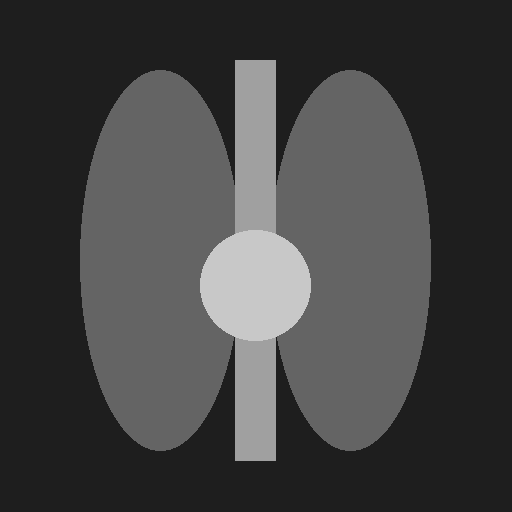

In [70]:
# Read PNG image

png_image = Image.open("sample_medical_image.png")

print("Image successfully loaded!")

print("Format :", png_image.format)
print("Size   :", png_image.size)
print("Mode   :", png_image.mode)

display(png_image)

In [71]:
# Convert PNG image into NumPy array

png_array = np.array(png_image)

print("Array shape :", png_array.shape)
print("Data type   :", png_array.dtype)
print("Min value   :", png_array.min())
print("Max value   :", png_array.max())

Array shape : (512, 512)
Data type   : uint8
Min value   : 30
Max value   : 200


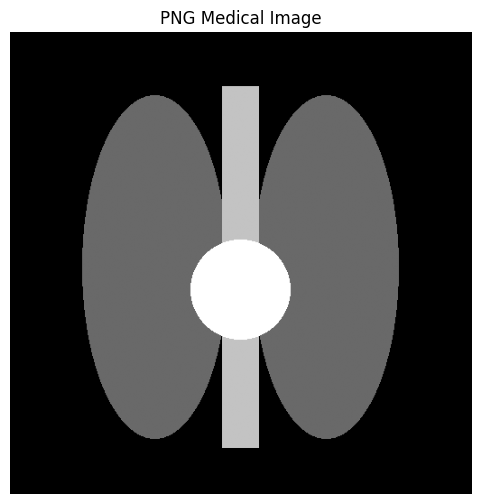

Original size: (512, 512)
Resized size : (224, 224)
Normalized   : Yes


In [72]:
# Normalize and resize PNG image

png_normalized = png_array / 255.0

png_resized = png_image.resize((224, 224))

plt.figure(figsize=(6, 6))

plt.imshow(
    png_normalized,
    cmap="gray"
)

plt.title("PNG Medical Image")
plt.axis("off")

plt.show()

print("Original size:", png_image.size)
print("Resized size :", png_resized.size)
print("Normalized   : Yes")